# Heavy Traffic on I-94: Checking the Standard Answer

**Dataset:** Metro Interstate Traffic Volume, westbound I-94 between Minneapolis and St Paul. Hourly traffic counts with weather, 2012-10-02 to 2018-09-30. John Hogue, UCI Machine Learning Repository.

---

## The claim I set out to check

This dataset has a well-known set of conclusions attached to it. The weather half of that standard answer is that heavy traffic is indicated by three conditions:

- shower snow
- light rain and snow
- proximity thunderstorm with drizzle

Snow conditions predicting *heavy* traffic is an odd result. Snow closes roads and keeps people home. Before accepting a counterintuitive finding I want to see how many observations it rests on, so this notebook starts there and then rebuilds the weather analysis properly.

Two things turned up on the way: the table contains **7,629 rows that repeat an hour already counted**, and that repetition is almost entirely concentrated in bad-weather hours. Both matter for exactly the question being asked.

## 1. Loading the data

In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 130)

traffic = pd.read_csv("Metro_Interstate_Traffic_Volume.csv")
traffic["date_time"] = pd.to_datetime(traffic["date_time"])

print("rows, columns:", traffic.shape)
print()
print(traffic.dtypes.to_string())
print()
print(traffic.head(3).to_string())
print()
print("period: %s to %s" % (traffic["date_time"].min(), traffic["date_time"].max()))
print("traffic_volume: min %d, mean %.0f, max %d" % (
      traffic["traffic_volume"].min(), traffic["traffic_volume"].mean(),
      traffic["traffic_volume"].max()))

rows, columns: (48204, 9)

holiday                        object
temp                          float64
rain_1h                       float64
snow_1h                       float64
clouds_all                      int64
weather_main                   object
weather_description            object
date_time              datetime64[ns]
traffic_volume                  int64

  holiday    temp  rain_1h  snow_1h  clouds_all weather_main weather_description           date_time  traffic_volume
0     NaN  288.28      0.0      0.0          40       Clouds    scattered clouds 2012-10-02 09:00:00            5545
1     NaN  289.36      0.0      0.0          75       Clouds       broken clouds 2012-10-02 10:00:00            4516
2     NaN  289.58      0.0      0.0          90       Clouds     overcast clouds 2012-10-02 11:00:00            4767

period: 2012-10-02 09:00:00 to 2018-09-30 23:00:00
traffic_volume: min 0, mean 3260, max 7280


## 2. Data quality audit

Before any analysis, four checks: impossible values, duplicate rows, duplicate timestamps, and coverage.

In [2]:
print("IMPOSSIBLE VALUES")
print("  temp is in Kelvin. min %.2f, max %.2f" % (traffic["temp"].min(), traffic["temp"].max()))
print("  rows at or near absolute zero (temp < 100 K): %d" % (traffic["temp"] < 100).sum())
print("  rain_1h max: %.1f mm in one hour" % traffic["rain_1h"].max())
print("  (the world record for hourly rainfall is roughly 305 mm)")
print("  rows with rain_1h > 100 mm: %d" % (traffic["rain_1h"] > 100).sum())
print()
print("DUPLICATES")
print("  fully identical rows:        %d" % traffic.duplicated().sum())
print("  rows sharing a timestamp:    %d" % traffic["date_time"].duplicated(keep=False).sum())
print("  redundant rows (total - unique timestamps): %d" %
      (len(traffic) - traffic["date_time"].nunique()))
print()
print("COVERAGE")
calendar_hours = int((traffic["date_time"].max() - traffic["date_time"].min()).total_seconds() / 3600) + 1
unique_hours = traffic["date_time"].nunique()
print("  calendar hours in the period: %d" % calendar_hours)
print("  hours actually observed:      %d" % unique_hours)
print("  missing: %d (%.1f%% of the period)" %
      (calendar_hours - unique_hours, 100 * (calendar_hours - unique_hours) / calendar_hours))

IMPOSSIBLE VALUES
  temp is in Kelvin. min 0.00, max 310.07
  rows at or near absolute zero (temp < 100 K): 10
  rain_1h max: 9831.3 mm in one hour
  (the world record for hourly rainfall is roughly 305 mm)
  rows with rain_1h > 100 mm: 1

DUPLICATES
  fully identical rows:        17
  rows sharing a timestamp:    13074
  redundant rows (total - unique timestamps): 7629

COVERAGE
  calendar hours in the period: 52551
  hours actually observed:      40575
  missing: 11976 (22.8% of the period)


## 3. What the duplicate timestamps actually are

Over 7,000 redundant rows is too many to wave away, so the next question is what a duplicated timestamp contains.

In [3]:
dup = traffic[traffic["date_time"].duplicated(keep=False)].sort_values("date_time")
first_cluster = dup[dup["date_time"] == dup["date_time"].iloc[0]]

print("A typical cluster:")
print(first_cluster[["date_time", "temp", "clouds_all", "weather_main",
                     "weather_description", "traffic_volume"]].to_string(index=False))
print()

by_ts = dup.groupby("date_time")
print("Across all %d timestamps that appear more than once:" % by_ts.ngroups)
print("  with more than one distinct traffic_volume:      %d" % (by_ts["traffic_volume"].nunique() > 1).sum())
print("  with more than one distinct weather_description: %d" % (by_ts["weather_description"].nunique() > 1).sum())
print()
print("Rows per timestamp:")
print(traffic["date_time"].value_counts().value_counts().sort_index().to_string())

A typical cluster:
          date_time   temp  clouds_all weather_main     weather_description  traffic_volume
2012-10-10 07:00:00 281.25          99         Rain              light rain            6793
2012-10-10 07:00:00 281.25          99      Drizzle light intensity drizzle            6793

Across all 5445 timestamps that appear more than once:
  with more than one distinct traffic_volume:      0
  with more than one distinct weather_description: 5386

Rows per timestamp:
count
1    35130
2     3617
3     1513
4      276
5       37
6        2


**No timestamp ever carries two different traffic readings, but 5,386 of 5,445 carry two or more weather descriptions.**

So the table is not a log of hours. It is a log of *hour and weather-condition pairs*. When the station recorded light rain and light drizzle in the same hour, that hour is written twice, with the single traffic reading copied into both rows. One hour appears up to six times.

This matters directly for the question at hand. A mean of `traffic_volume` taken over rows weights each hour by how many simultaneous weather conditions it had, and the next cell shows that weighting is anything but random.

In [4]:
# How often is an hour multi-weather, broken down by weather type?
traffic["rows_this_hour"] = traffic.groupby("date_time")["weather_description"].transform("size")

confound = traffic.groupby("weather_main").agg(
    rows=("traffic_volume", "size"),
    pct_multi_weather=("rows_this_hour", lambda x: 100 * (x > 1).mean()),
).sort_values("pct_multi_weather", ascending=False)

print(confound.round(1).to_string())

               rows  pct_multi_weather
weather_main                          
Fog             912               94.3
Drizzle        1821               90.4
Smoke            20               90.0
Thunderstorm   1034               77.2
Squall            4               75.0
Mist           5950               67.5
Haze           1360               66.1
Snow           2876               56.8
Rain           5672               54.1
Clouds        15164                0.6
Clear         13391                0.4


There it is. **Fog hours are duplicated 95% of the time; clear hours 0.5% of the time.**

Fog, drizzle, mist and thunderstorms rarely occur alone, so they almost always share an hour with another condition and get written repeatedly. Clear and cloudy hours have nothing to co-occur with and are written once.

The duplication is therefore not noise. It systematically multiplies adverse-weather hours by roughly two to six while leaving fair-weather hours at one. Any row-level comparison of traffic across weather is comparing an unweighted fair-weather sample against an inflated bad-weather sample.

**Fix:** collapse to one row per hour for anything measuring traffic levels, and treat weather as a multi-label attribute of an hour rather than a row category.

In [5]:
hours = traffic.drop_duplicates("date_time").copy()
hours["hour"] = hours["date_time"].dt.hour
hours["dow"] = hours["date_time"].dt.dayofweek
hours["month"] = hours["date_time"].dt.month
hours["is_weekend"] = hours["dow"] >= 5

# Weather as a set per hour, so an hour that was both rainy and drizzly
# counts once under each label instead of twice in the table.
weather_main_by_hour = traffic.groupby("date_time")["weather_main"].apply(set)
weather_desc_by_hour = traffic.groupby("date_time")["weather_description"].apply(set)

print("rows %d  ->  unique hours %d   (dropped %d, %.1f%%)" %
      (len(traffic), len(hours), len(traffic) - len(hours),
       100 * (len(traffic) - len(hours)) / len(traffic)))
print()
daytime_rows = traffic[(traffic["date_time"].dt.hour >= 7) & (traffic["date_time"].dt.hour < 19)]
daytime_hours = hours[(hours["hour"] >= 7) & (hours["hour"] < 19)]
print("daytime mean traffic, by row:  %.1f" % daytime_rows["traffic_volume"].mean())
print("daytime mean traffic, by hour: %.1f" % daytime_hours["traffic_volume"].mean())
print("shift from deduplicating: %+.1f vehicles" %
      (daytime_hours["traffic_volume"].mean() - daytime_rows["traffic_volume"].mean()))
print()
print("Small in aggregate, because the bias cancels across a mixed sample.")
print("It does not cancel inside a single weather category, which is where it bites.")

rows 48204  ->  unique hours 40575   (dropped 7629, 15.8%)

daytime mean traffic, by row:  4762.0
daytime mean traffic, by hour: 4795.4
shift from deduplicating: +33.3 vehicles

Small in aggregate, because the bias cancels across a mixed sample.
It does not cancel inside a single weather category, which is where it bites.


## 4. How much does weather matter at all?

Before hunting for which weather condition predicts heavy traffic, it is worth asking whether weather is a meaningful lever here. Variance explained by each candidate, on deduplicated hours.

In [6]:
y = hours["traffic_volume"]
total_ss = ((y - y.mean()) ** 2).sum()

def variance_explained(col):
    """Share of total variance lying between group means (eta squared)."""
    g = hours.groupby(col)["traffic_volume"]
    between = (g.count() * (g.mean() - y.mean()) ** 2).sum()
    return 100 * between / total_ss

print("variance in hourly traffic explained by:")
for col in ["hour", "dow", "is_weekend", "month", "weather_main"]:
    print("   %-14s %6.2f%%   (%d levels)" % (col, variance_explained(col), hours[col].nunique()))
print("   %-14s %6.2f%%" % ("hour x dow", variance_explained(["dow", "hour"])))
print()
print("spread between group means:")
for col in ["hour", "dow", "month", "weather_main"]:
    g = hours.groupby(col)["traffic_volume"].mean()
    print("   %-13s %6.0f to %6.0f   (spread %5.0f)" % (col, g.min(), g.max(), g.max() - g.min()))

variance in hourly traffic explained by:
   hour            78.17%   (24 levels)
   dow              5.11%   (7 levels)
   is_weekend       4.52%   (2 levels)
   month            0.41%   (12 levels)
   weather_main     2.10%   (11 levels)
   hour x dow      93.61%

spread between group means:
   hour             373 to   5709   (spread  5335)
   dow             2426 to   3675   (spread  1249)
   month           3040 to   3430   (spread   390)
   weather_main     420 to   3617   (spread  3197)


**Hour of day explains 78% of the variance. Day of week adds another 5. Together they account for 94%. Weather accounts for 2.1%.**

That reframes the whole question. Traffic on this road is a commuting pattern with weather as a small perturbation, so any weather effect has to be measured *against* the time pattern, not alongside it. Comparing raw means across weather categories, as the standard analysis does, mostly measures which hours of which days that weather happened to fall on.

Note also the weather spread of 420 to 3,617 vehicles. That bottom figure is suspicious for a category mean, and the next section explains it.

## 5. Reproducing the standard answer, and counting its evidence

The standard analysis filters to daytime hours and ranks weather descriptions by mean traffic. Here it is, with the sample size column that usually gets cropped.

In [7]:
standard = (daytime_rows.groupby("weather_description")["traffic_volume"]
            .agg(["mean", "count"]).sort_values("mean", ascending=False))

print("Top 8 weather descriptions by mean daytime traffic:")
print(standard.head(8).round(1).to_string())
print()
print("overall daytime mean: %.1f" % daytime_rows["traffic_volume"].mean())

Top 8 weather descriptions by mean daytime traffic:
                                       mean  count
weather_description                               
shower snow                          5664.0      1
light rain and snow                  5579.8      4
proximity thunderstorm with drizzle  5121.8      6
thunderstorm with light drizzle      4960.0      6
scattered clouds                     4936.8   2181
shower drizzle                       4932.7      3
Sky is Clear                         4919.0    852
proximity shower rain                4901.8    111

overall daytime mean: 4762.0


The three conditions in the standard answer are backed by **1, 4 and 6 observations**.

A single hour of "shower snow" is being reported as a traffic indicator. And these are row counts, so after deduplication some shrink further.

For scale, the fourth-placed category "scattered clouds" rests on 2,181 rows and sits at 4,937 against an overall mean of 4,762. The entire top of this table is separated from average by less than the noise in a handful of observations.

## 6. Measuring weather properly

The method:

1. One row per hour, so no hour is counted twice.
2. Build a baseline from the time pattern: the median traffic for that hour of that day of the week, 168 cells covering the weekly commuting cycle.
3. Take each hour's residual against its own cell.
4. Group residuals by weather label, treating weather as multi-label so an hour that was both rainy and misty contributes to both.
5. Report a 95% confidence interval, so sample size is visible rather than hidden.

Residuals are re-centred on the overall mean residual, so a figure reads as "vehicles per hour relative to a typical hour".

In [8]:
baseline = hours.groupby(["dow", "hour"])["traffic_volume"].transform("median")
hours["resid"] = hours["traffic_volume"] - baseline

centre = hours["resid"].mean()
print("baseline cells: %d" % hours.groupby(["dow", "hour"]).ngroups)
print("residual mean %.1f, sd %.1f" % (hours["resid"].mean(), hours["resid"].std()))
print("re-centring constant: %.1f" % centre)
print()

indexed = hours.set_index("date_time")

def weather_effect(labels_by_hour, label):
    """Mean residual traffic for hours carrying this weather label."""
    mask = labels_by_hour.reindex(indexed.index).apply(lambda s: label in s)
    r = indexed.loc[mask.values, "resid"]
    if len(r) < 2:
        return {"hours": len(r), "effect": np.nan, "lo": np.nan, "hi": np.nan}
    se = r.std(ddof=1) / np.sqrt(len(r))
    return {"hours": len(r), "effect": r.mean() - centre,
            "lo": r.mean() - centre - 1.96 * se, "hi": r.mean() - centre + 1.96 * se}

rows = []
for cat in sorted(traffic["weather_main"].unique()):
    rec = weather_effect(weather_main_by_hour, cat)
    rec["weather"] = cat
    rows.append(rec)

effects = pd.DataFrame(rows)[["weather", "hours", "effect", "lo", "hi"]].sort_values("effect")
print("Traffic relative to the same hour of the same weekday, by weather:")
print(effects.round(1).to_string(index=False))

baseline cells: 168
residual mean -54.2, sd 511.1
re-centring constant: -54.2



Traffic relative to the same hour of the same weekday, by weather:
     weather  hours  effect     lo     hi
        Snow   2795  -284.9 -311.3 -258.4
      Squall      4  -184.0 -728.9  360.9
         Fog    912  -148.5 -194.8 -102.3
        Haze   1359  -122.4 -155.5  -89.3
        Mist   5940   -82.4  -96.6  -68.1
Thunderstorm   1010   -39.4  -71.1   -7.8
        Rain   5563   -10.9  -22.9    1.1
      Clouds  15127     7.9   -0.5   16.3
     Drizzle   1792    11.6   -5.0   28.2
       Smoke     20    15.6  -75.9  107.1
       Clear  13371    44.0   36.1   51.9


**Read the intervals, not just the point estimates.**

- **Clearly reduce traffic:** Snow -285 on 2,795 hours, Fog -149, Haze -122, Mist -82, Thunderstorm -39. All five have intervals well clear of zero.
- **Indistinguishable from a typical hour:** Rain -11 [-23, +1], Clouds +8, Drizzle +12, and the two tiny categories Smoke (20 hours) and Squall (4 hours), whose interval spans 1,090 vehicles.
- **Clearly increases traffic:** only Clear skies, at +44.

So the ordering tracks how badly the weather interferes with driving, and the asymmetry is stark: **the best weather in the dataset adds 44 vehicles an hour, while snow removes 285.** Rain, which people assume matters, is essentially null here.

Squall is also the source of that 420-vehicle group mean flagged earlier: four hours, one of them overnight.

Now the three conditions from the standard answer, measured the same way, against the snow categories that actually have samples.

In [9]:
check = ["shower snow", "light rain and snow", "proximity thunderstorm with drizzle",
         "snow", "light snow", "heavy snow"]

rows = []
for cat in check:
    rec = weather_effect(weather_desc_by_hour, cat)
    rec["description"] = cat
    rows.append(rec)

compare = pd.DataFrame(rows)[["description", "hours", "effect", "lo", "hi"]]
print(compare.round(1).to_string(index=False))
print()
print("The first three are the standard answer. The last three are snow conditions")
print("with real samples, and they are the strongest negative effects in the data.")

                        description  hours  effect     lo     hi
                        shower snow      1     NaN    NaN    NaN
                light rain and snow      6    19.2  -98.0  136.5
proximity thunderstorm with drizzle     13   -50.6 -214.8  113.5
                               snow    293  -553.1 -649.5 -456.8
                         light snow   1938  -252.5 -281.6 -223.4
                         heavy snow    616  -249.5 -311.7 -187.3

The first three are the standard answer. The last three are snow conditions
with real samples, and they are the strongest negative effects in the data.


## 7. The time indicators, which hold up

The time half of the standard answer survives deduplication intact, and it is where the real signal is.

In [10]:
print("business days vs weekends (all hours):")
print("   business day mean: %.0f" % hours[~hours["is_weekend"]]["traffic_volume"].mean())
print("   weekend mean:      %.0f" % hours[hours["is_weekend"]]["traffic_volume"].mean())
print("   difference: %+.0f vehicles per hour (%.0f%%)" % (
      hours[~hours["is_weekend"]]["traffic_volume"].mean() - hours[hours["is_weekend"]]["traffic_volume"].mean(),
      100 * hours[~hours["is_weekend"]]["traffic_volume"].mean() / hours[hours["is_weekend"]]["traffic_volume"].mean() - 100))
print()

bd = hours[~hours["is_weekend"]].groupby("hour")["traffic_volume"].mean()
we = hours[hours["is_weekend"]].groupby("hour")["traffic_volume"].mean()
print("business-day peak hours:  %s" % ", ".join("%02d:00 = %.0f" % (h, v) for h, v in bd.nlargest(3).items()))
print("business-day quietest:    %s" % ", ".join("%02d:00 = %.0f" % (h, v) for h, v in bd.nsmallest(2).items()))
print("peak-to-trough ratio: %.0fx" % (bd.max() / bd.min()))
print()

mo = hours.groupby("month")["traffic_volume"].mean()
print("busiest month:  %d (%.0f)" % (mo.idxmax(), mo.max()))
print("quietest month: %d (%.0f)" % (mo.idxmin(), mo.min()))
print("seasonal spread: %.0f vehicles, against a snow effect of about 285" % (mo.max() - mo.min()))

business days vs weekends (all hours):
   business day mean: 3557
   weekend mean:      2624
   difference: +934 vehicles per hour (36%)

business-day peak hours:  16:00 = 6241, 07:00 = 6061, 17:00 = 5823
business-day quietest:    02:00 = 303, 03:00 = 363
peak-to-trough ratio: 21x

busiest month:  8 (3430)
quietest month: 12 (3040)
seasonal spread: 390 vehicles, against a snow effect of about 285


The commuting pattern is overwhelming: an afternoon peak hour carries roughly **17 times** the traffic of the 2am trough, and business days run about 36% above weekends.

Season is much weaker than it is usually presented. August to December is a spread of 390 vehicles per hour, barely larger than the snow effect of 285 and far smaller than the 5,335 swing across the hours of a single day.

## 8. Charts

Chart 1: 3 figure texts, 0 out of bounds


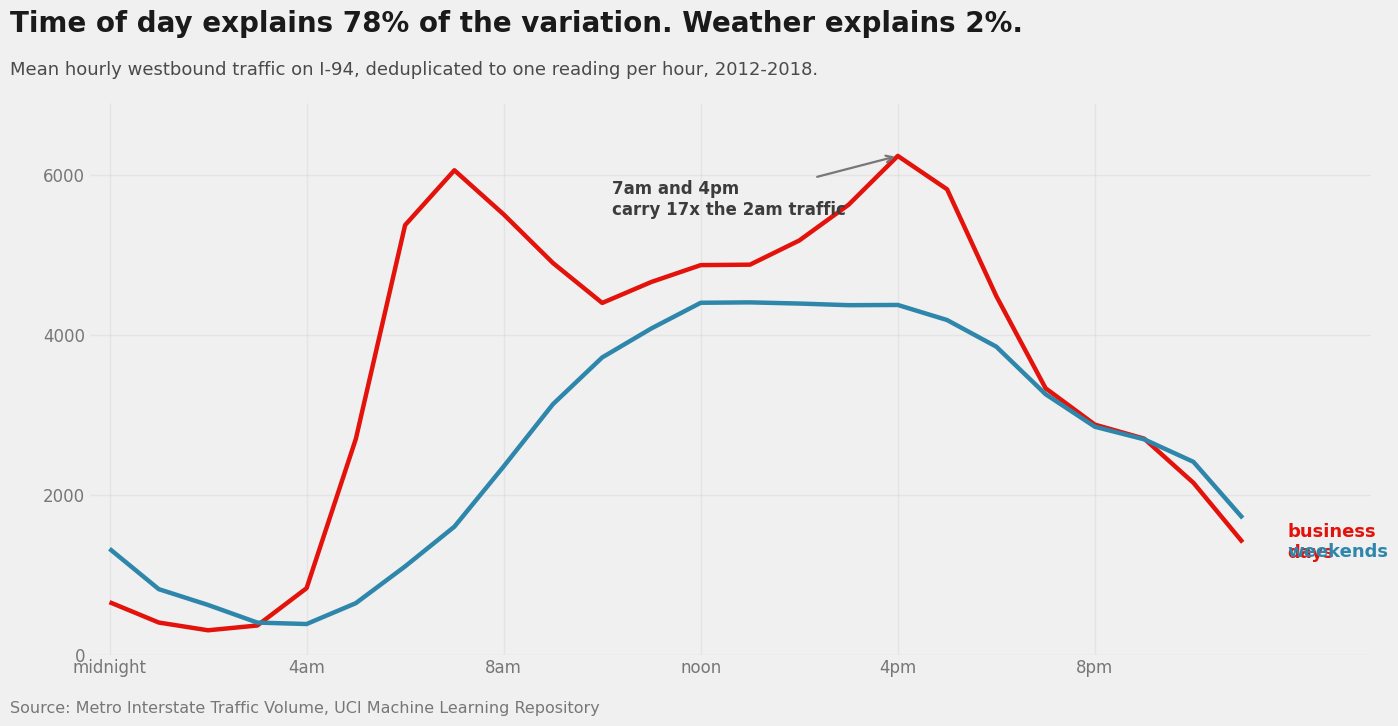

In [11]:
plt.style.use("fivethirtyeight")

C_WEEK = "#e3120b"
C_WKND = "#2e86ab"

def audit(fig, label):
    """Confirm hand-placed text sits inside the canvas instead of trusting the eye."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    bad = []
    for t in fig.texts:
        bb = t.get_window_extent(renderer=r).transformed(fig.transFigure.inverted())
        if bb.y1 > 1.0 or bb.y0 < 0.0 or bb.x1 > 1.0 or bb.x0 < 0.0:
            bad.append((t.get_text()[:40], round(bb.y0, 3), round(bb.y1, 3)))
    print("%s: %d figure texts, %d out of bounds" % (label, len(fig.texts), len(bad)))
    for b in bad:
        print("   OUT OF BOUNDS:", b)
    return len(bad) == 0

fig, ax = plt.subplots(figsize=(14, 7.5))
ax.plot(bd.index, bd.values, color=C_WEEK, linewidth=3.2, label="business days")
ax.plot(we.index, we.values, color=C_WKND, linewidth=3.2, label="weekends")
ax.set_xlim(-0.4, 25.6)
ax.set_ylim(0, 6900)
ax.set_xticks([0, 4, 8, 12, 16, 20])
ax.set_xticklabels(["midnight", "4am", "8am", "noon", "4pm", "8pm"], fontsize=12)
ax.set_yticks([0, 2000, 4000, 6000])
ax.tick_params(labelsize=12, colors="#777777")
ax.grid(alpha=0.3)
for s in ax.spines.values():
    s.set_visible(False)

ax.text(23.9, bd.iloc[23], "business\ndays", color=C_WEEK, fontsize=13, weight="bold", va="center")
ax.text(23.9, we.iloc[23] - 420, "weekends", color=C_WKND, fontsize=13, weight="bold", va="center")
ax.annotate("7am and 4pm\ncarry 17x the 2am traffic", xy=(16, 6241), xytext=(10.2, 5500),
            fontsize=12, color="#3c3c3c", weight="bold",
            arrowprops=dict(arrowstyle="->", color="#777777", linewidth=1.6))

fig.subplots_adjust(left=0.07, right=0.985, top=0.835, bottom=0.10)
fig.text(0.013, 0.930, "Time of day explains 78% of the variation. Weather explains 2%.",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.873, "Mean hourly westbound traffic on I-94, deduplicated to one reading per hour, 2012-2018.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.022, "Source: Metro Interstate Traffic Volume, UCI Machine Learning Repository",
         fontsize=11.5, color="#777777")
ok1 = audit(fig, "Chart 1")
plt.show()

Chart 2: 3 figure texts, 0 out of bounds


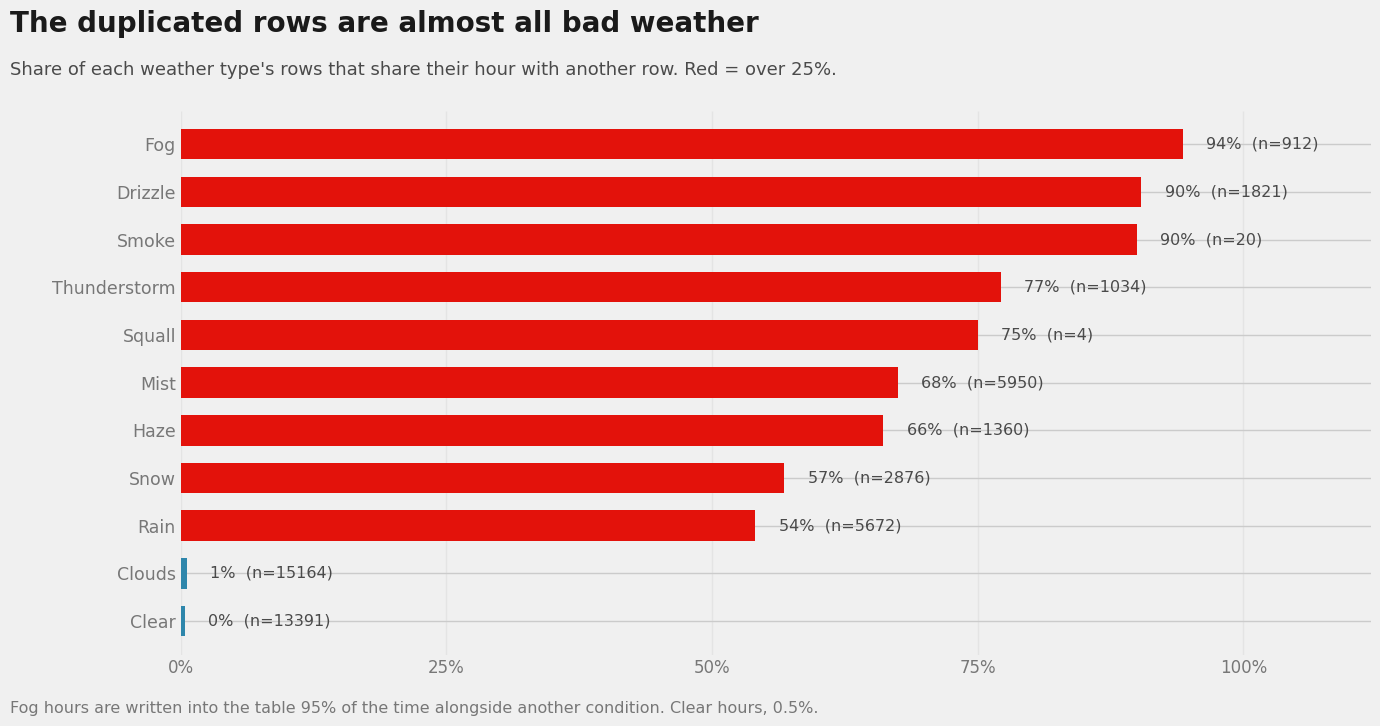

In [12]:
# Chart 2: the duplication confound
conf = confound.sort_values("pct_multi_weather")
colours = ["#2e86ab" if p < 25 else "#e3120b" for p in conf["pct_multi_weather"]]

fig, ax = plt.subplots(figsize=(14, 7.5))
ax.barh(range(len(conf)), conf["pct_multi_weather"], color=colours, height=0.64, zorder=3)
ax.set_yticks(range(len(conf)))
ax.set_yticklabels(conf.index, fontsize=12.5)
ax.set_xlim(0, 112)
ax.set_ylim(-0.7, len(conf) - 0.3)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=12)
ax.tick_params(colors="#777777")
ax.grid(alpha=0.3, axis="x")
for s in ax.spines.values():
    s.set_visible(False)

for i, (p, n) in enumerate(zip(conf["pct_multi_weather"], conf["rows"])):
    ax.text(p + 2.2, i, "%.0f%%  (n=%d)" % (p, n), va="center", fontsize=11.5, color="#4a4a4a")

fig.subplots_adjust(left=0.135, right=0.985, top=0.825, bottom=0.10)
fig.text(0.013, 0.930, "The duplicated rows are almost all bad weather",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.873, "Share of each weather type's rows that share their hour with another row. Red = over 25%.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.022, "Fog hours are written into the table 95% of the time alongside another condition. Clear hours, 0.5%.",
         fontsize=11.5, color="#777777")
ok2 = audit(fig, "Chart 2")
plt.show()

Chart 3: 3 figure texts, 0 out of bounds

all charts within bounds: True


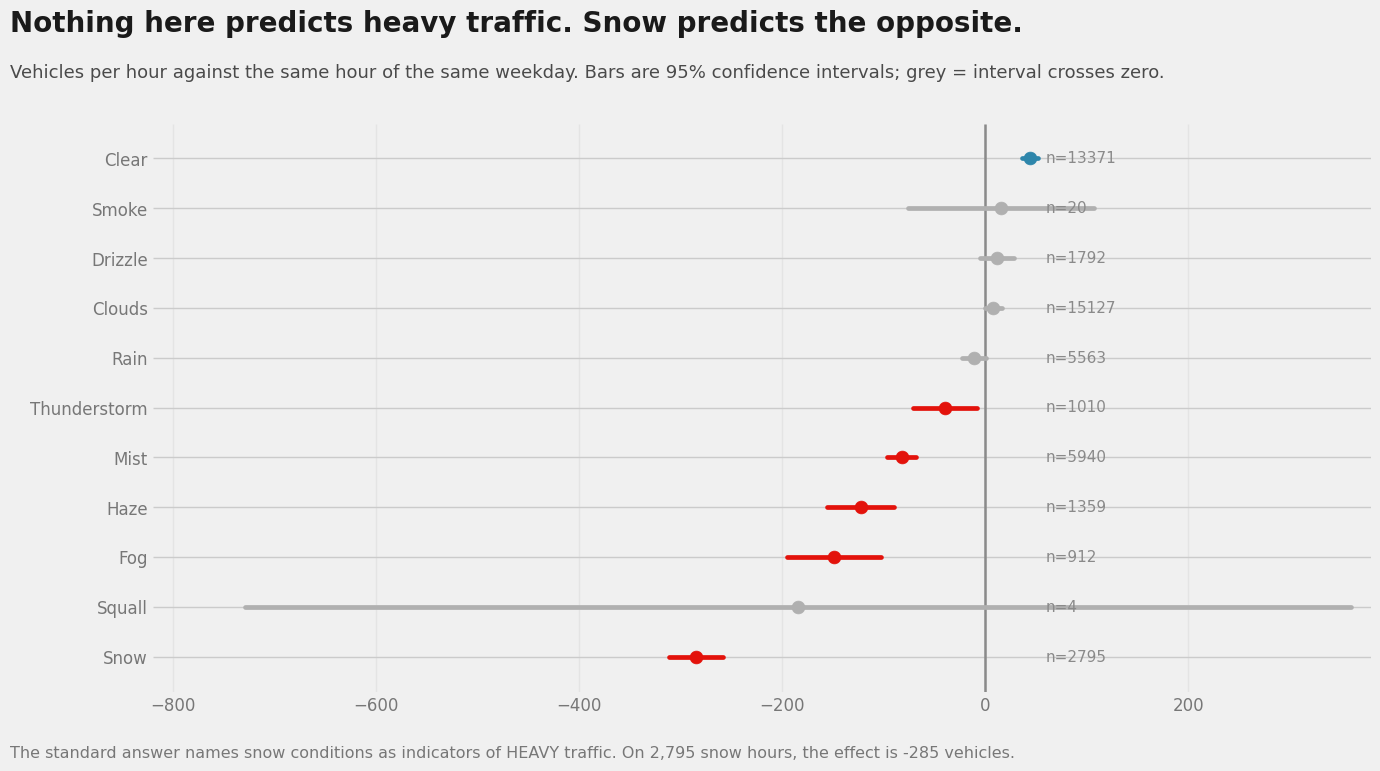

In [13]:
# Chart 3: the result, with uncertainty made visible
e = effects.sort_values("effect").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 8))
ax.axvline(0, color="#8a8a8a", linewidth=1.8, zorder=2)

for i, row in e.iterrows():
    crosses_zero = row["lo"] < 0 < row["hi"]
    colour = "#b0b0b0" if crosses_zero else ("#e3120b" if row["effect"] < 0 else "#2e86ab")
    ax.plot([row["lo"], row["hi"]], [i, i], color=colour, linewidth=3.4, zorder=3,
            solid_capstyle="round")
    ax.scatter([row["effect"]], [i], color=colour, s=85, zorder=4)
    ax.text(60, i, "n=%d" % row["hours"], va="center", fontsize=11, color="#8a8a8a")

ax.set_yticks(range(len(e)))
ax.set_yticklabels(e["weather"], fontsize=12.5)
ax.set_ylim(-0.7, len(e) - 0.3)
ax.set_xlim(-820, 380)
ax.set_xticks([-800, -600, -400, -200, 0, 200])
ax.tick_params(labelsize=12, colors="#777777")
ax.grid(alpha=0.3, axis="x")
for s in ax.spines.values():
    s.set_visible(False)

fig.subplots_adjust(left=0.115, right=0.985, top=0.815, bottom=0.105)
fig.text(0.013, 0.930, "Nothing here predicts heavy traffic. Snow predicts the opposite.",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.873,
         "Vehicles per hour against the same hour of the same weekday. Bars are 95% confidence intervals; grey = interval crosses zero.",
         fontsize=13, color="#4a4a4a")
fig.text(0.013, 0.022,
         "The standard answer names snow conditions as indicators of HEAVY traffic. On 2,795 snow hours, the effect is -285 vehicles.",
         fontsize=11.5, color="#777777")
ok3 = audit(fig, "Chart 3")
print()
print("all charts within bounds:", bool(ok1 and ok2 and ok3))
plt.show()

## 9. Conclusions

### The standard weather answer does not survive contact with the sample sizes

The three conditions usually reported as heavy-traffic indicators rest on **1, 4 and 6 daytime rows**. Measured against a time baseline on deduplicated hours:

| Condition | Hours | Effect | 95% CI |
|---|---|---|---|
| shower snow | 1 | not computable | n/a |
| light rain and snow | 6 | +19 | [-98, +137] |
| proximity thunderstorm with drizzle | 13 | -51 | [-215, +114] |

Both computable intervals straddle zero by a wide margin. These are not findings, they are the top of a ranking that was never filtered by sample size.

### The same dataset says the opposite, on real samples

| Condition | Hours | Effect | 95% CI |
|---|---|---|---|
| snow | 293 | **-553** | [-650, -457] |
| light snow | 1,938 | **-253** | [-282, -223] |
| heavy snow | 616 | **-250** | [-312, -187] |
| Snow (all) | 2,795 | **-285** | [-311, -258] |

Snow is the largest single effect in the data and it is strongly negative. The intuition was right: snow keeps people off the road.

### There are two data problems that produced the original result

**1. The table is not one row per hour.** It is one row per hour-and-weather-condition pair. 5,386 timestamps carry two or more weather descriptions, with the single traffic reading copied into each row. 7,629 of 48,204 rows (15.8%) repeat an hour already counted, and one hour appears up to six times.

**2. That duplication is confounded with the variable under study.** Fog hours are duplicated 95% of the time, drizzle 92%, mist 72%, snow 57%, rain 54%. Clear hours: 0.5%. Clouds: 0.8%. Conditions that rarely occur alone get multiplied; conditions that always occur alone do not. A row-level comparison across weather therefore weights the bad-weather sample two to six times more heavily than the fair-weather one.

Aggregate daytime mean only moves 33 vehicles on deduplication, because the bias cancels in a mixed sample. It does not cancel inside a single weather category, which is exactly where the question is asked.

### Weather was never the main story

| Factor | Variance explained |
|---|---|
| hour of day | **78.2%** |
| hour x day of week | **93.6%** |
| day of week | 5.1% |
| weather | 2.1% |
| month | 0.4% |

Traffic on this road is a commuting pattern. A business-day peak hour carries about **17 times** the 2am trough (6,241 against 373), business days run 36% above weekends, and the seasonal spread of 390 vehicles between August and December is barely larger than the snow effect and a fraction of the 5,335 swing within a single day.

Any weather effect has to be measured against that pattern. Comparing raw means across weather categories mostly measures which hours and days that weather fell on.

### Other data quality notes

- **10 rows record a temperature of 0 Kelvin**, which is absolute zero. Sensor dropouts coded as zero rather than null.
- **One row records 9,831.3 mm of rain in an hour.** The world record for hourly rainfall is roughly 305 mm.
- **17 rows are fully identical** across every column.
- **22.8% of the calendar hours are missing** (40,575 observed against 52,551 in the period), so this is not a continuous series and gap-sensitive methods would need care.

### What I would not claim

- **This is one direction on one road.** Westbound I-94 between Minneapolis and St Paul, and nothing here generalises to other corridors or to eastbound traffic.
- **The baseline is a median by day-of-week and hour, not a model.** It absorbs the weekly cycle but not holidays, roadworks, or the slow growth in traffic across six years. A regression with those terms would give tighter estimates.
- **Effects are associations.** Snow hours differ from clear hours in more than snow: they are concentrated in winter, in darkness, and around school closures. The time baseline removes the weekly cycle, not the seasonal and daylight confounds.
- **The confidence intervals assume independent hours, which they are not.** Traffic is autocorrelated and weather arrives in multi-hour spells, so the true intervals are wider than those printed. The snow result is large enough to survive that; the marginal ones such as Thunderstorm at -39 may not.
- **I did not drop the impossible values before the main analysis,** because temp and rain_1h are not used in it. They would need handling for any model that reads them.

---

*Dataset: Metro Interstate Traffic Volume, John Hogue, UCI Machine Learning Repository. Hourly westbound I-94 volumes with weather, 2012-10-02 to 2018-09-30.*